# 04 · What the land becomes after forest loss

Hansen gives one loss year per pixel and says nothing about what follows (whether the land stay cleared or grow back). In Guinea most loss is shifting cultivation (82 %, WRI/DeepMind drivers in the forest loss drivers study), where fields are cleared, cropped for a few years and left to grow back (Curtis et al. 2018). So a large part of the loss should regrow. This matters for two things:

* comparing Hansen with NERF, which reports deforestation (forest to non-forest) separately from degradation;
* the target of the deforestation model: all loss, or only loss that stays.

Loss here is canopy above 30 % in 2000 (the threshold chosen in notebook 03) and loss in 2013–2016: from the 2013 method change, and early enough that every later year of Esri (2017–2025) comes after it. **Undisturbed forest** (canopy above 30 %, no loss) is the control: what the maps say where nothing happened shows their noise.

All values come from the stage-1 point tables (one point per 4.3 km² hexagon); no new Earth Engine reads.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path.cwd().parent / "output_datasets" / "lulc_benchmark"      # saved by ../lulc_benchmark.ipynb
OUT = Path.cwd() / "output"
read = lambda key: pd.read_parquet(DATA / f"{key}_h3res7.parquet").set_index("point_id")

points = read("sample_points")
weights = points["weight_km2"]
hansen, esri, glad, tmf = read("hansen"), read("esri"), read("glad_glclu"), read("tmf")

COMMON = {1: "Tree cover", 2: "Shrub & grassland", 3: "Cropland", 4: "Built-up", 5: "Bare", 6: "Water", 7: "Herbaceous wetland"}
CLASS_COLORS = {"Tree cover": "#2e7d32", "Shrub & grassland": "#c5b358", "Cropland": "#f39c12", "Built-up": "#c0392b",
                "Bare": "#a1887f", "Water": "#2980b9", "Herbaceous wetland": "#7fcdbb"}   # as in ../lulc_benchmark.ipynb
esri = esri.apply(lambda c: c.map({1: 6, 2: 1, 4: 7, 5: 3, 7: 4, 8: 5, 11: 2}))   # stage-1 crosswalk to the common legend

forest = hansen.treecover2000 > 30
groups = {"Lost in 2013–2016": forest & hansen.lossyear.between(13, 16), "Undisturbed forest": forest & (hansen.lossyear == 0)}


def share(mask, values):
    # Area share (%) of each value among the points in `mask`; each point stands for its hexagon.
    w = weights[mask]
    return 100 * w.groupby(values[mask]).sum() / w.sum()


for name, mask in groups.items():
    print(f"{name}: {mask.sum():,} points, {weights[mask].sum():,.0f} km²")

Lost in 2013–2016: 1,527 points, 6,599 km²
Undisturbed forest: 13,581 points, 57,460 km²


## 1 · Land cover in the years after the loss

Esri's class at each point, each year from 2017 to 2025.

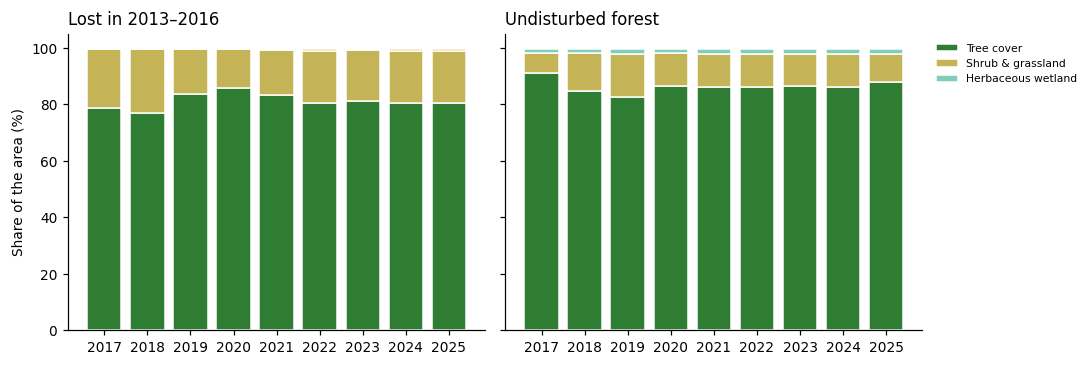

Tree cover  Shrub & grassland  Cropland  Built-up
Lost in 2013–2016  2017        78.8               20.8       0.4       0.1
                   2018        77.0               22.5       0.3       0.1
                   2019        83.6               16.0       0.3       0.2
                   2020        85.6               13.8       0.3       0.2
                   2021        83.3               15.8       0.5       0.2
                   2022        80.6               18.3       0.5       0.3
                   2023        81.2               18.0       0.3       0.3
                   2024        80.4               18.6       0.6       0.2
                   2025        80.3               18.5       0.7       0.2
Undisturbed forest 2017        91.0                7.3       0.0       0.2
                   2018        84.8               13.3       0.0       0.2
                   2019        82.6               15.2       0.0       0.2
                   2020        86.5               11.5       0.0       0.3
                   2021        86.1               11.9       0.1       0.3
                   2022        86.3               11.6       0.1       0.3
                   2023        86.5               11.4       0.0       0.2
                   2024        86.2               11.7       0.1       0.3
                   2025        88.1                9.7       0.1       0.3

In [2]:
cover = pd.concat({name: pd.DataFrame({year: share(mask, esri[year]) for year in esri.columns}).T
                   for name, mask in groups.items()}).fillna(0).rename(columns=COMMON)
cover.round(1).to_csv(OUT / "04_land_cover_after_loss.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, name in zip(axes, groups):
    table = cover.loc[name]
    bottom = np.zeros(len(table))
    for cls in [c for c in CLASS_COLORS if c in table and table[c].max() >= 0.5]:
        ax.bar(table.index, table[cls], bottom=bottom, color=CLASS_COLORS[cls], width=0.8, edgecolor="white", linewidth=1, label=cls)
        bottom += table[cls].values
    ax.set_title(name, loc="left")
axes[0].set_ylabel("Share of the area (%)")
axes[1].legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=7, frameon=False)
plt.tight_layout(); plt.show()
cover.loc[:, ["Tree cover", "Shrub & grassland", "Cropland", "Built-up"]].round(1)

**Reading:**

* **From 2017 on, Esri calls about 80 % of the 2013–2016 loss tree cover**, close to the 83–91 % it gives undisturbed forest. The rest is mostly shrub & grassland.
* **Cropland and built-up stay under 1 %.** Esri hardly maps cropland in Guinea (it calls most of it grassland, notebook 02), so these maps cannot tell a field from a fallow.

## 2 · How fast the trees come back

All loss years 2013–2024, by the number of years between the loss and Esri's map. The dashed line is the share of undisturbed forest Esri calls tree cover, averaged over 2017–2025.

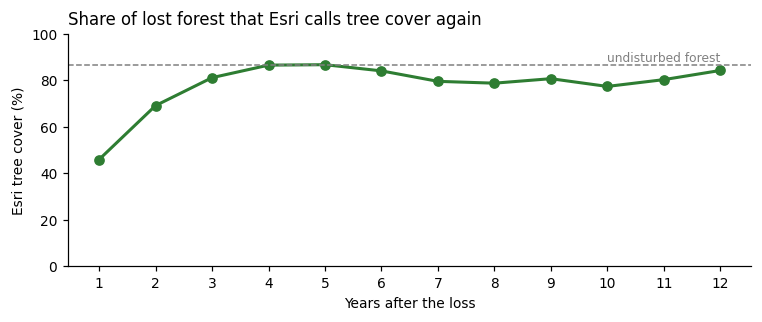

years after the loss,1,2,3,4,5,6,7,8,9,10,11,12
tree cover (%),45.9,69.1,81.2,86.5,86.7,84.1,79.6,78.8,80.7,77.4,80.3,84.2


In [3]:
rows = []
for loss_year in range(13, 25):
    lost = forest & (hansen.lossyear == loss_year)
    for year in esri.columns:
        years_after = int(year) - 2000 - loss_year
        if years_after >= 1:
            rows.append({"years after the loss": years_after, "tree km²": weights[lost & (esri[year] == 1)].sum(),
                         "km²": weights[lost & esri[year].notna()].sum()})
regrowth = pd.DataFrame(rows).groupby("years after the loss").sum()
regrowth["tree cover (%)"] = 100 * regrowth["tree km²"] / regrowth["km²"]
undisturbed = np.mean([share(groups["Undisturbed forest"], esri[y]).get(1, 0) for y in esri.columns])
regrowth.round(1).to_csv(OUT / "04_regrowth_by_years_after_loss.csv")

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(regrowth.index, regrowth["tree cover (%)"], marker="o", color="#2e7d32", linewidth=2)
ax.axhline(undisturbed, color="grey", linestyle="--", linewidth=1)
ax.text(regrowth.index[-1], undisturbed + 1.5, "undisturbed forest", color="grey", ha="right", fontsize=8)
ax.set_xlabel("Years after the loss")
ax.set_ylabel("Esri tree cover (%)")
ax.set_ylim(0, 100)
ax.set_xticks(regrowth.index)
ax.set_title("Share of lost forest that Esri calls tree cover again", loc="left")
plt.tight_layout(); plt.show()
regrowth["tree cover (%)"].round(1).to_frame().T

**Reading:** one year after the loss, about half the area is tree cover again; after three to four years, about as much as in undisturbed forest. This is the fallow cycle of shifting cultivation: the land is cleared, used briefly and left to regrow.

The same, split by when the loss happened and by ecoregion (one to five years after the loss). Esri starts in 2017, so for the loss of 2013–2016 the first year after is the loss of 2016 only.

In [4]:
def regrowth_by(groups_of):
    # Esri tree cover (%) 1-5 years after the loss, for groups of loss points; groups_of(loss_year) gives {group: mask}.
    rows = []
    for loss_year in range(13, 25):
        lost = forest & (hansen.lossyear == loss_year)
        for year in esri.columns:
            years_after = int(year) - 2000 - loss_year
            if 1 <= years_after <= 5:
                for group, mask in groups_of(loss_year).items():
                    rows.append({"group": group, "years after the loss": years_after,
                                 "tree km²": weights[lost & mask & (esri[year] == 1)].sum(),
                                 "km²": weights[lost & mask & esri[year].notna()].sum()})
    table = pd.DataFrame(rows).groupby(["group", "years after the loss"]).sum()
    return (100 * table["tree km²"] / table["km²"]).unstack()


everywhere = pd.Series(True, index=points.index)
periods = {"Lost in 2013–2016": range(13, 17), "Lost in 2017–2020": range(17, 21), "Lost in 2021–2024": range(21, 25)}
by_period = regrowth_by(lambda ly: {name: everywhere for name, years in periods.items() if ly in years})
by_eco = regrowth_by(lambda ly: {eco: points["ECO_NAME"] == eco for eco in
                                 ["Guinean forest-savanna", "Western Guinean lowland forests", "Guinean montane forests"]})
regrowth_split = pd.concat({"By loss period": by_period, "By ecoregion": by_eco})
regrowth_split.round(1).to_csv(OUT / "04_regrowth_by_period_and_ecoregion.csv")
regrowth_split.round(1)

years after the loss                               1     2     3     4     5
               group                                                        
By loss period Lost in 2013–2016                66.0  73.0  81.8  87.4  87.1
               Lost in 2017–2020                41.2  67.6  81.3  85.5  86.4
               Lost in 2021–2024                44.9  68.4  79.5  88.3   NaN
By ecoregion   Guinean forest-savanna           37.5  63.8  79.0  84.7  84.6
               Guinean montane forests          31.7  59.3  72.4  82.4  86.5
               Western Guinean lowland forests  80.9  92.4  94.7  96.3  95.0

**Reading:**

* **When the loss happened does not change the speed.** From the second year on, the loss of 2013–2016, 2017–2020 and 2021–2024 regrows alike: about 70 % tree cover after two years, 80 % after three, 86–88 % after four.
* **The ecoregion does.** In the lowland forests 81 % is tree cover again after one year; in the forest-savanna and montane forests about a third, and 80 % only after three to four years.
* So what matters is the time since the loss: **whether a loss stays can only be judged three to four years after it**, and the loss of the last three years cannot be judged yet.

## 3 · Tree height before and after

Esri's tree cover does not say whether the trees are a young fallow or a forest. GLAD's land cover (Potapov et al. 2022) gives tree height, for 2010 (before the loss) and 2020 (4–7 years after).

In [5]:
def height_class(code):
    # GLAD GLCLU legend: 25-48 trees on dry land and 125-148 in wetlands, height = code - 22 m; 244 cropland; 250 built-up
    code = int(code)
    if 25 <= code % 100 <= 48 and code < 150:
        height = code % 100 - 22
        return "Trees under 5 m" if height < 5 else "Trees 5–10 m" if height < 10 else "Trees 10 m or taller"
    return {244: "Cropland", 250: "Built-up"}.get(code, "Short vegetation" if 2 <= code <= 24 else "Other")


heights = pd.concat({(name, year): share(mask, glad[year].map(height_class)) for name, mask in groups.items()
                     for year in ("2010", "2020")}, axis=1).fillna(0).T
order = ["Trees 10 m or taller", "Trees 5–10 m", "Trees under 5 m", "Short vegetation", "Cropland", "Built-up", "Other"]
heights = heights[[c for c in order if c in heights]]
heights.round(1).to_csv(OUT / "04_tree_height_before_after.csv")
heights.round(1)

Trees 10 m or taller  Trees 5–10 m  Trees under 5 m  \
Lost in 2013–2016  2010                  45.4          41.6              9.1   
                   2020                  15.7          47.6             28.1   
Undisturbed forest 2010                  69.6          23.8              2.7   
                   2020                  63.0          27.0              5.3   

                         Short vegetation  Cropland  Built-up  Other  
Lost in 2013–2016  2010               3.7       0.0       0.2    0.1  
                   2020               7.6       0.1       0.5    0.3  
Undisturbed forest 2010               1.6       0.0       0.2    2.1  
                   2020               2.1       0.0       0.5    2.1

**Reading:**

* **Before the loss, 45 % of the area had trees 10 m or taller; four to seven years after, 16 %.** Trees under 5 m went from 9 % to 28 %. In undisturbed forest, tall trees went only from 70 % to 63 %.
* Only about 8 % had no trees in 2020, and GLAD's cropland is near zero. So the land grows back, but as young, short trees: a fallow, not the forest that was there.

## 4 · By ecoregion

Esri's class in the last three years (2023–2025): tree cover every year, never tree cover, or switching. "Never tree cover" is the closest these maps come to permanent clearing; the same share for undisturbed forest is Esri's noise.

In [6]:
last = esri[["2023", "2024", "2025"]] == 1
path = pd.Series(np.select([last.all(axis=1), ~last.any(axis=1)], ["Tree cover every year", "Never tree cover"], "Switching"),
                 index=esri.index)
rows = {}
for eco in ["All Guinea", "Guinean forest-savanna", "Western Guinean lowland forests", "Guinean montane forests"]:
    in_eco = pd.Series(True, index=points.index) if eco == "All Guinea" else points["ECO_NAME"] == eco
    for name, mask in groups.items():
        rows[(eco, name)] = share(mask & in_eco, path)
        rows[(eco, name)]["Points"] = (mask & in_eco).sum()
by_ecoregion = pd.DataFrame(rows).T.fillna(0)[["Points", "Tree cover every year", "Switching", "Never tree cover"]]
by_ecoregion.round(1).to_csv(OUT / "04_after_loss_by_ecoregion.csv")
by_ecoregion.round(1)

Points  \
All Guinea                      Lost in 2013–2016    1527.0   
                                Undisturbed forest  13581.0   
Guinean forest-savanna          Lost in 2013–2016     974.0   
                                Undisturbed forest   8330.0   
Western Guinean lowland forests Lost in 2013–2016     341.0   
                                Undisturbed forest   2879.0   
Guinean montane forests         Lost in 2013–2016     176.0   
                                Undisturbed forest   1629.0   

                                                    Tree cover every year  \
All Guinea                      Lost in 2013–2016                    65.6   
                                Undisturbed forest                   81.7   
Guinean forest-savanna          Lost in 2013–2016                    59.5   
                                Undisturbed forest                   81.7   
Western Guinean lowland forests Lost in 2013–2016                    82.9   
                                Undisturbed forest                   82.7   
Guinean montane forests         Lost in 2013–2016                    71.5   
                                Undisturbed forest                   79.9   

                                                    Switching  \
All Guinea                      Lost in 2013–2016        27.7   
                                Undisturbed forest       10.1   
Guinean forest-savanna          Lost in 2013–2016        32.7   
                                Undisturbed forest       10.7   
Western Guinean lowland forests Lost in 2013–2016        13.5   
                                Undisturbed forest        6.9   
Guinean montane forests         Lost in 2013–2016        22.7   
                                Undisturbed forest       13.3   

                                                    Never tree cover  
All Guinea                      Lost in 2013–2016                6.7  
                                Undisturbed forest               8.3  
Guinean forest-savanna          Lost in 2013–2016                7.8  
                                Undisturbed forest               7.6  
Western Guinean lowland forests Lost in 2013–2016                3.5  
                                Undisturbed forest              10.4  
Guinean montane forests         Lost in 2013–2016                5.8  
                                Undisturbed forest               6.8

The mangroves (24 lost points) and the West Sudanian savanna (12) have too few points to show.

**Reading:**

* **The share that never returns to tree cover is no higher after loss than in undisturbed forest** (7 % against 8 % for all of Guinea). With these maps, permanent clearing cannot be told apart from Esri's errors.
* **In the forest-savanna, a third of the lost area switches** between trees and grassland from one year to the next, against about 10 % in undisturbed forest: fallows being cleared again, or young regrowth that Esri cannot place.
* **In the lowland forests, the lost area is as much tree cover as undisturbed forest** by 2023–2025.

## 5 · Maps

The points lost in 2013–2016: left, by Esri's class in 2023–2025 (section 4); right, by GLAD's tree height in 2020 (section 3). The shares in the legends are of the lost area.

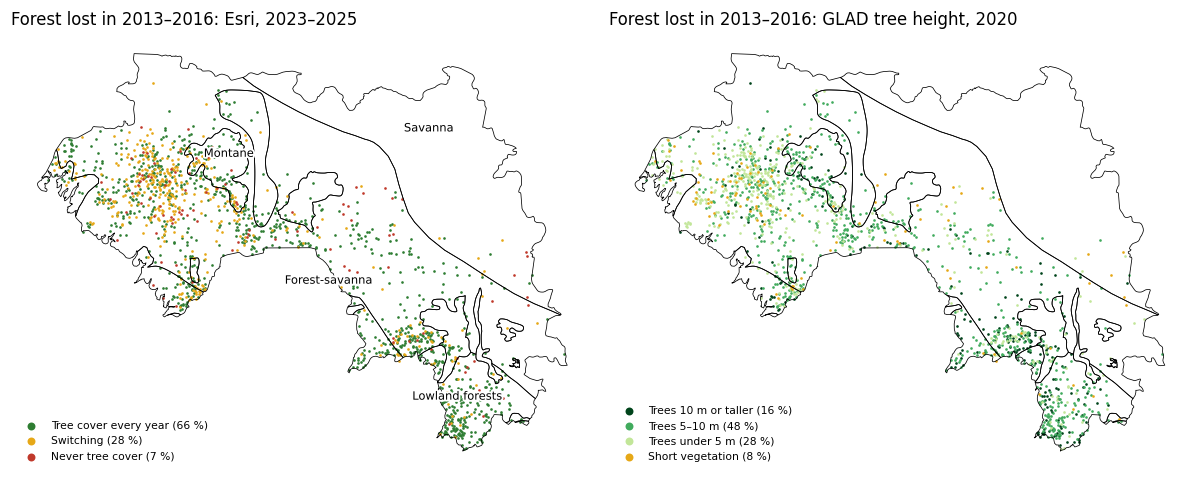

In [7]:
STUDIES = Path.cwd().parent

import geopandas as gpd
import matplotlib.patheffects as pe

ecoregions = gpd.read_file(STUDIES / "output_datasets" / "ecoregions_guinea.gpkg", layer="ecoregions_guinea").to_crs(4326)
SHORT_NAMES = {"West Sudanian savanna": ("Savanna", -9.6, 11.6), "Guinean forest-savanna": ("Forest-savanna", -11.0, 9.5),
               "Western Guinean lowland forests": ("Lowland forests", -9.2, 7.9), "Guinean montane forests": ("Montane", -12.4, 11.25)}


def draw_ecoregions(ax, names=True):
    # Ecoregion borders, with short names on the left panel.
    ecoregions.boundary.plot(ax=ax, color="black", linewidth=0.5)
    if names:
        for name, x, y in SHORT_NAMES.values():
            ax.text(x, y, name, fontsize=7.5, ha="center", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])
    ax.set_axis_off()

lost = points[groups["Lost in 2013–2016"]]
height_2020 = glad.loc[lost.index, "2020"].map(height_class)
PANELS = [(path[lost.index], "Esri, 2023–2025", {"Tree cover every year": "#2e7d32", "Switching": "#e6a817", "Never tree cover": "#c0392b"}),
          (height_2020, "GLAD tree height, 2020", {"Trees 10 m or taller": "#00441b", "Trees 5–10 m": "#41ab5d",
                                                   "Trees under 5 m": "#c2e699", "Short vegetation": "#e6a817"})]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, (values, title, colours) in zip(axes, PANELS):
    for label, colour in colours.items():
        sub = lost[values == label]
        share_pct = 100 * sub.weight_km2.sum() / lost.weight_km2.sum()
        ax.scatter(sub.lon, sub.lat, s=3, color=colour, linewidths=0, label=f"{label} ({share_pct:.0f} %)")
    ax.legend(loc="lower left", frameon=False, fontsize=7, markerscale=3)
    ax.set_title(f"Forest lost in 2013–2016: {title}", loc="left")
draw_ecoregions(axes[0]); draw_ecoregions(axes[1], names=False)
plt.tight_layout(); plt.show()

**Reading:** the switching points and the youngest trees (under 5 m) are concentrated in the west of the forest-savanna, where most of the loss is, with a smaller group at the edge of the lowland forests. In the lowland forests themselves, the lost points are mostly tree cover every year, with trees of 5 m or taller. The points that never return to tree cover are scattered, with no cluster that would point to a mine, a town or a plantation.

## 6 · Moist forest: what JRC TMF says

TMF follows moist forest year by year and has its own classes for land deforested and for forest regrowing (Vancutsem et al. 2021). It covers only 3.4 % of Guinea (notebook 01), so this is the south-east only.

In [8]:
TMF_CLASSES = {1: "Undisturbed", 2: "Degraded", 3: "Deforested", 4: "Regrowing", 5: "Water", 6: "Other land"}
moist_loss = groups["Lost in 2013–2016"] & tmf["2012"].isin([1, 2, 4])
tmf_after = pd.crosstab(tmf.loc[moist_loss, "2025"].map(TMF_CLASSES).rename("TMF class in 2025"),
                        path[moist_loss].rename("Esri, 2023–2025"), margins=True, margins_name="Total")
print(f"Lost in 2013–2016 inside TMF's moist forest: {moist_loss.sum()} points")
tmf_after

Lost in 2013–2016 inside TMF's moist forest: 155 points


"Esri, 2023–2025",Never tree cover,Switching,Tree cover every year,Total
TMF class in 2025,,,,
Deforested,4,11,67,82
Degraded,0,2,34,36
Regrowing,0,0,35,35
Undisturbed,0,0,2,2
Total,4,13,138,155


**Reading:** TMF still calls about half of this loss deforested in 2025 and a quarter regrowing, where Esri calls most of it tree cover. Both can be right: the trees are back, but not yet as moist forest. TMF is stricter about what counts as forest again.

## 7 · What this means

* **Most of Hansen's loss in Guinea grows back.** Esri sees tree cover again within three years; GLAD sees short trees four to seven years later. This fits shifting cultivation as the main driver. The speed depends on the ecoregion, not on the year of the loss.
* **The permanent part cannot be measured with these maps.** Esri's share that never returns to tree cover (7 %) is no higher than in undisturbed forest; GLAD's share without trees in 2020 (8.5 %) is 4 points higher. At most about a tenth of the loss, about 180 km² a year at 30 % canopy, stays without trees. This is expected: annual global maps confuse young fallow, grassland and cropland (notebook 02), and telling a fallow from a permanent field needs interpreters who see the land use. Permanent loss is needed to report deforestation under the national definition and for emissions; the risk model, which predicts where clearing happens, does not need it.
* **NERF's deforestation (637 km² a year) lies between that and Hansen's total loss (1,770 km²).** So NERF probably counts some clearing that later regrows as deforestation. The NERF report should say how it treats fallow clearing; this decides how the two can be compared.
* **For the deforestation model:**
  * keep all of Hansen's loss as the target and call it forest loss, as decided; a target of permanent loss cannot be built from these maps;
  * the land cleared is often young fallow, and Hansen records one loss per pixel, so a pixel cleared again after regrowing is not counted twice. Past loss nearby is likely a strong predictor: fallows get cleared again;
  * the forest at risk at the start of each period should be the forest that is there then. Hansen's forest is the forest of 2000 minus the loss since: a pixel drops out once cleared, even after it grows back, and fallows that grew back are never added. So a regrown fallow that is cleared again is outside the forest at risk, and its clearing is not counted. Whether a recent forest map that counts regrowth does better is the next test in the deforestation experiments.

### References

* Curtis, P.G., Slay, C.M., Harris, N.L., Tyukavina, A., Hansen, M.C. (2018). Classifying drivers of global forest loss. *Science* 361, 1108–1111.
* Hansen, M.C., et al. (2013). High-resolution global maps of 21st-century forest cover change. *Science* 342, 850–853.
* Karra, K., Kontgis, C., Statman-Weil, Z., et al. (2021). Global land use/land cover with Sentinel 2 and deep learning. *IGARSS 2021*, 4704–4707.
* Potapov, P., Hansen, M.C., Pickens, A., et al. (2022). The global 2000–2020 land cover and land use change dataset derived from the Landsat archive: first results. *Frontiers in Remote Sensing* 3, 856903.
* République de Guinée (2026). *Niveau de référence des forêts (NRF) et niveau d'émissions de référence des forêts (NERF) de la Guinée, période 2016–2020*. Submitted to the UNFCCC.
* Sims, M.J., et al. (2025). Global drivers of forest loss at 1 km resolution. *Environmental Research Letters* 20, 074027.
* Vancutsem, C., Achard, F., Pekel, J.-F., et al. (2021). Long-term (1990–2019) monitoring of forest cover changes in the humid tropics. *Science Advances* 7, eabe1603.